In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

Loading the dataset


In [3]:
student_info = pd.read_csv("studentInfo.csv")
student_registration = pd.read_csv("studentRegistration.csv")

student_vle = pd.read_csv(
    "studentVle.csv",
    engine="python",
    on_bad_lines="skip"
)

vle = pd.read_csv("vle.csv")
student_assessment = pd.read_csv("studentAssessment.csv")
assessments = pd.read_csv("assessments.csv")
courses = pd.read_csv("courses.csv")

print("studentInfo:", student_info.shape)
print("studentVle:", student_vle.shape)
print("vle:", vle.shape)
print("studentAssessment:", student_assessment.shape)
print("assessments:", assessments.shape)
print("courses:", courses.shape)

studentInfo: (32593, 12)
studentVle: (7562848, 6)
vle: (6364, 6)
studentAssessment: (173912, 5)
assessments: (206, 6)
courses: (22, 3)


In [5]:
datasets = {
    "studentInfo": student_info,
    "studentVle": student_vle,
    "vle": vle,
    "studentAssessment": student_assessment,
    "assessments": assessments,
    "courses": courses
}

for name, data in datasets.items():
    print("=" * 50)
    print(name)
    print("Rows:", data.shape[0])
    print("Columns:", data.shape[1])
    print("Duplicates:", data.duplicated().sum())
    print("Missing values:", data.isnull().sum().sum())

studentInfo
Rows: 32593
Columns: 12
Duplicates: 0
Missing values: 1111
studentVle
Rows: 7562848
Columns: 6
Duplicates: 535331
Missing values: 0
vle
Rows: 6364
Columns: 6
Duplicates: 0
Missing values: 10486
studentAssessment
Rows: 173912
Columns: 5
Duplicates: 0
Missing values: 173
assessments
Rows: 206
Columns: 6
Duplicates: 0
Missing values: 11
courses
Rows: 22
Columns: 3
Duplicates: 0
Missing values: 0


In [6]:
student_info["Completion_Status"] = student_info["final_result"].map({
    "Pass": 1,
    "Distinction": 1,
    "Fail": 0,
    "Withdrawn": 0
})

print(student_info["Completion_Status"].value_counts())

Completion_Status
0    17208
1    15385
Name: count, dtype: int64


In [7]:
login_frequency = (
    student_vle
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )["date"]
    .nunique()
    .reset_index(name="Login_Frequency")
)

In [8]:
total_activity = (
    student_vle
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )["sum_click"]
    .sum()
    .reset_index(name="Total_Activity")
)

In [9]:
student_vle_details = student_vle.merge(
    vle[["id_site", "activity_type"]],
    on="id_site",
    how="left"
)

video_activity = (
    student_vle_details[
        student_vle_details["activity_type"].str.contains(
            "video", case=False, na=False
        )
    ]
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )["sum_click"]
    .sum()
    .reset_index(name="Video_Activity")
)

In [10]:
assessment_details = student_assessment.merge(
    assessments[
        [
            "id_assessment",
            "code_module",
            "code_presentation",
            "assessment_type"
        ]
    ],
    on="id_assessment",
    how="left"
)

quiz_attempts = (
    assessment_details[
        assessment_details["assessment_type"] == "CMA"
    ]
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )["id_assessment"]
    .nunique()
    .reset_index(name="Quiz_Attempts")
)

assignment_submissions = (
    assessment_details[
        assessment_details["assessment_type"] == "TMA"
    ]
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )["id_assessment"]
    .nunique()
    .reset_index(name="Assignment_Submissions")
)

In [11]:
discussion_activity = (
    student_vle_details[
        student_vle_details["activity_type"].str.contains(
            "forum|discussion",
            case=False,
            na=False
        )
    ]
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )["sum_click"]
    .sum()
    .reset_index(name="Discussion_Activity")
)

Create Final Project Dataset

In [12]:
project_df = student_info[
    [
        "id_student",
        "code_module",
        "code_presentation",
        "Completion_Status"
    ]
].copy()

features = [
    login_frequency,
    total_activity,
    video_activity,
    quiz_attempts,
    assignment_submissions,
    discussion_activity
]

for feature in features:
    project_df = project_df.merge(
        feature,
        on=[
            "id_student",
            "code_module",
            "code_presentation"
        ],
        how="left"
    )

activity_columns = [
    "Login_Frequency",
    "Total_Activity",
    "Video_Activity",
    "Quiz_Attempts",
    "Assignment_Submissions",
    "Discussion_Activity"
]

project_df[activity_columns] = (
    project_df[activity_columns].fillna(0)
)

project_df = project_df.rename(
    columns={
        "id_student": "Learner_ID",
        "code_module": "Course_ID"
    }
)

display(project_df.head())

,Learner_ID,Course_ID,code_presentation,Completion_Status,Login_Frequency,Total_Activity,Video_Activity,Quiz_Attempts,Assignment_Submissions,Discussion_Activity
0,11391,AAA,2013J,1,40.0,934.0,0.0,0.0,5.0,193.0
1,28400,AAA,2013J,1,80.0,1435.0,0.0,0.0,5.0,417.0
2,30268,AAA,2013J,0,12.0,281.0,0.0,0.0,0.0,126.0
3,31604,AAA,2013J,1,123.0,2158.0,0.0,0.0,5.0,634.0
4,32885,AAA,2013J,1,70.0,1034.0,0.0,0.0,5.0,194.0


In [13]:
project_df.to_csv(
    "MOOC_Dropout_Processed.csv",
    index=False
)

In [14]:
completion_rate = (
    project_df["Completion_Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(f"Completed     : {completion_rate.get(1, 0):.2f}%")
print(f"Not Completed : {completion_rate.get(0, 0):.2f}%")

Completed     : 47.20%
Not Completed : 52.80%


In [15]:
behavior_cols = [
    "Login_Frequency",
    "Video_Activity",
    "Quiz_Attempts",
    "Assignment_Submissions",
    "Discussion_Activity"
]

behavior_summary = (
    project_df
    .groupby("Completion_Status")[behavior_cols]
    .mean()
    .round(2)
)

behavior_summary.index = [
    "Not Completed",
    "Completed"
]

display(behavior_summary)

,Login_Frequency,Video_Activity,Quiz_Attempts,Assignment_Submissions,Discussion_Activity
Not Completed,18.21,0.0,0.85,1.52,68.59
Completed,66.88,0.0,3.63,4.69,333.07


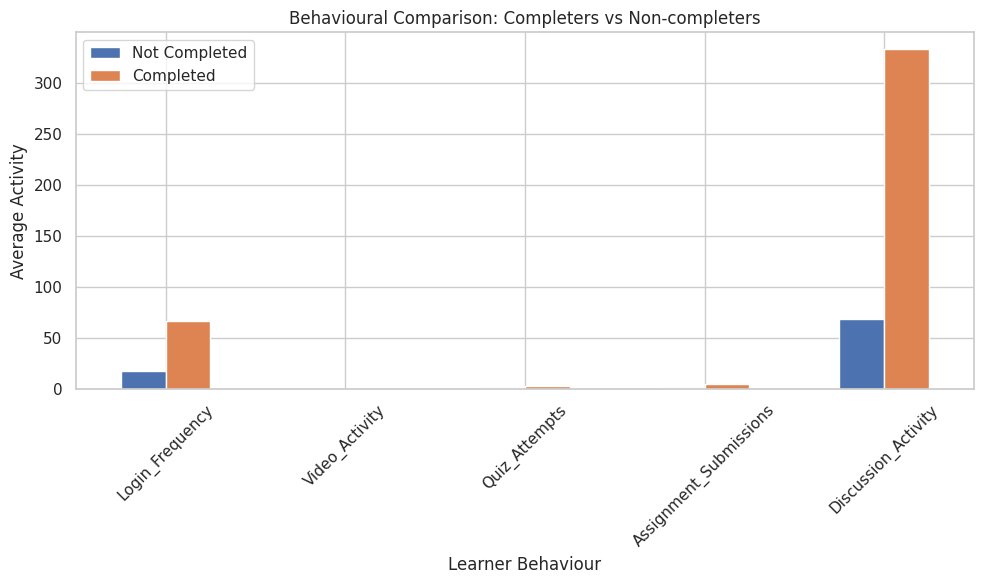

In [16]:
plot_data = (
    project_df
    .groupby("Completion_Status")[behavior_cols]
    .mean()
)

plot_data.index = [
    "Not Completed",
    "Completed"
]

plot_data.T.plot(kind="bar", figsize=(10, 6))

plt.title("Behavioural Comparison: Completers vs Non-completers")
plt.xlabel("Learner Behaviour")
plt.ylabel("Average Activity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
course_summary = (
    project_df
    .groupby("Course_ID")
    .agg(
        Learners=("Learner_ID", "count"),
        Completion_Rate=("Completion_Status", "mean")
    )
    .reset_index()
)

course_summary["Completion_Rate"] *= 100

display(course_summary.round(2))

,Course_ID,Learners,Completion_Rate
0,AAA,748,70.99
1,BBB,7909,47.46
2,CCC,4434,37.84
3,DDD,6272,41.61
4,EEE,2934,56.24
5,FFF,7762,47.00
6,GGG,2534,59.75


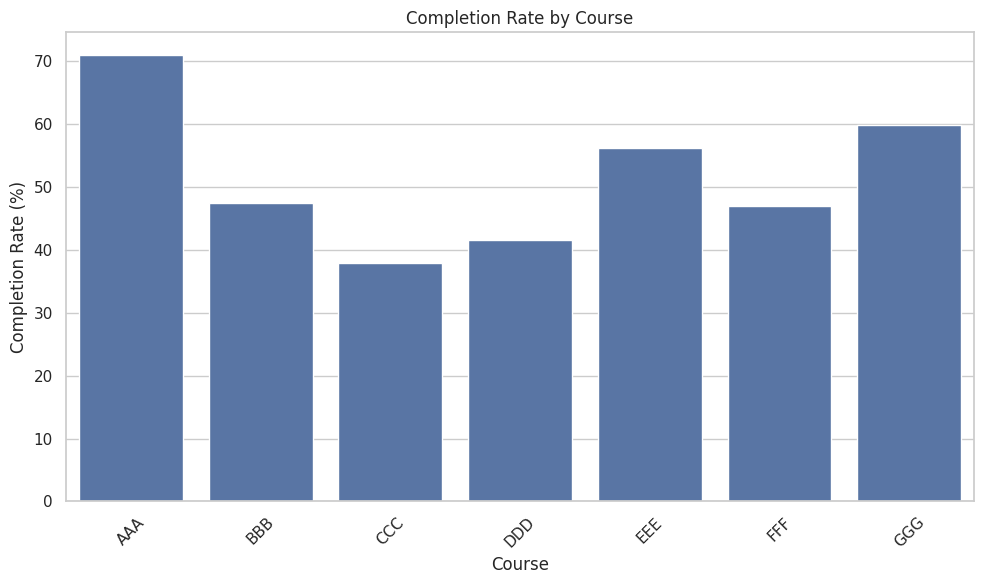

In [18]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=course_summary,
    x="Course_ID",
    y="Completion_Rate"
)

plt.title("Completion Rate by Course")
plt.xlabel("Course")
plt.ylabel("Completion Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
student_vle["Stage"] = pd.cut(
    student_vle["date"],
    bins=[-1, 10, 20, 30],
    labels=["Early", "Middle", "Late"]
)

stage_activity = (
    student_vle
    .groupby("Stage", observed=False)["sum_click"]
    .sum()
    .reset_index()
)

stage_activity["Activity_Percentage"] = (
    stage_activity["sum_click"]
    / stage_activity["sum_click"].sum()
    * 100
)

display(stage_activity)

,Stage,sum_click,Activity_Percentage
0,Early,2380104,36.060641
1,Middle,2470310,37.427340
2,Late,1749868,26.512019


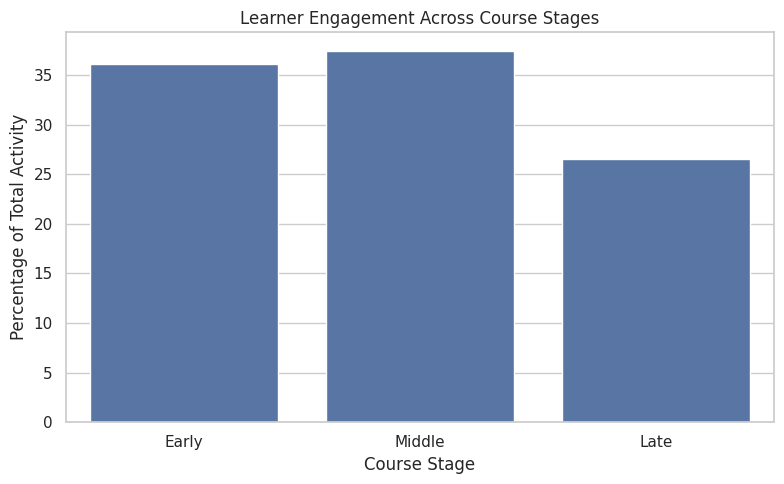

In [20]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=stage_activity,
    x="Stage",
    y="Activity_Percentage"
)

plt.title("Learner Engagement Across Course Stages")
plt.xlabel("Course Stage")
plt.ylabel("Percentage of Total Activity")
plt.tight_layout()
plt.show()

In [21]:
early_activity = (
    student_vle[student_vle["date"] <= 7]
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )
    .agg(
        Early_Activity=("sum_click", "sum"),
        Early_Active_Days=("date", "nunique")
    )
    .reset_index()
)

early_df = student_info[
    [
        "id_student",
        "code_module",
        "code_presentation",
        "Completion_Status"
    ]
].merge(
    early_activity,
    on=[
        "id_student",
        "code_module",
        "code_presentation"
    ],
    how="left"
)

early_df[
    ["Early_Activity", "Early_Active_Days"]
] = early_df[
    ["Early_Activity", "Early_Active_Days"]
].fillna(0)

early_summary = (
    early_df
    .groupby("Completion_Status")
    [["Early_Activity", "Early_Active_Days"]]
    .mean()
    .round(2)
)

early_summary.index = [
    "Not Completed",
    "Completed"
]

display(early_summary)

,Early_Activity,Early_Active_Days
Not Completed,66.09,3.48
Completed,150.47,6.26


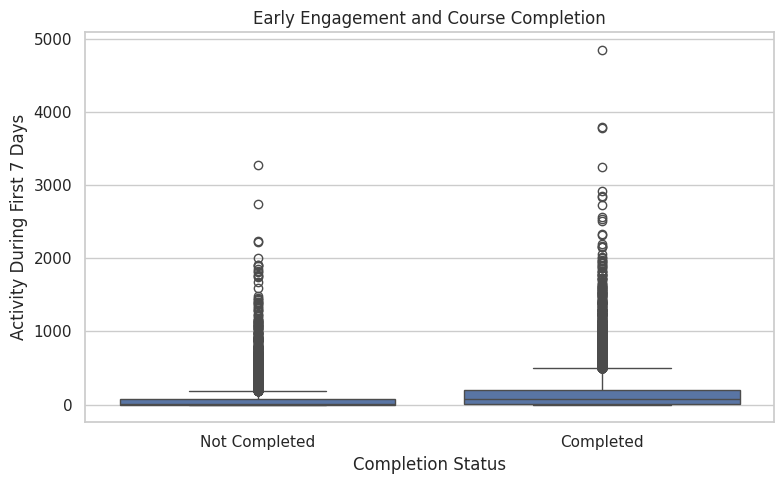

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=early_df,
    x="Completion_Status",
    y="Early_Activity"
)

plt.title("Early Engagement and Course Completion")
plt.xlabel("Completion Status")
plt.ylabel("Activity During First 7 Days")
plt.xticks(
    [0, 1],
    ["Not Completed", "Completed"]
)

plt.tight_layout()
plt.show()

RANDOM FOREST

In [23]:
early_vle = student_vle[
    student_vle["date"] <= 7
].merge(
    vle[["id_site", "activity_type"]],
    on="id_site",
    how="left"
)

early_login = (
    early_vle
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )["date"]
    .nunique()
    .reset_index(name="Early_Login_Frequency")
)

early_video = (
    early_vle[
        early_vle["activity_type"].str.contains(
            "video", case=False, na=False
        )
    ]
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )["sum_click"]
    .sum()
    .reset_index(name="Early_Video_Activity")
)

early_discussion = (
    early_vle[
        early_vle["activity_type"].str.contains(
            "forum|discussion",
            case=False,
            na=False
        )
    ]
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )["sum_click"]
    .sum()
    .reset_index(name="Early_Discussion_Activity")
)

early_assessment = assessment_details[
    assessment_details["date_submitted"] <= 7
]

early_quiz = (
    early_assessment[
        early_assessment["assessment_type"] == "CMA"
    ]
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )["id_assessment"]
    .nunique()
    .reset_index(name="Early_Quiz_Attempts")
)

early_assignment = (
    early_assessment[
        early_assessment["assessment_type"] == "TMA"
    ]
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )["id_assessment"]
    .nunique()
    .reset_index(name="Early_Assignment_Submissions")
)

In [24]:
early_model = student_info[
    [
        "id_student",
        "code_module",
        "code_presentation",
        "Completion_Status"
    ]
].copy()

for feature in [
    early_login,
    early_video,
    early_quiz,
    early_assignment,
    early_discussion
]:
    early_model = early_model.merge(
        feature,
        on=[
            "id_student",
            "code_module",
            "code_presentation"
        ],
        how="left"
    )

feature_cols = [
    "Early_Login_Frequency",
    "Early_Video_Activity",
    "Early_Quiz_Attempts",
    "Early_Assignment_Submissions",
    "Early_Discussion_Activity"
]

early_model[feature_cols] = (
    early_model[feature_cols].fillna(0)
)

In [25]:
X = early_model[feature_cols]
y = early_model["Completion_Status"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

In [26]:
print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred):.3f}")
print(f"Recall   : {recall_score(y_test, y_pred):.3f}")
print(f"F1 Score : {f1_score(y_test, y_pred):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.3f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy : 0.611
Precision: 0.617
Recall   : 0.464
F1 Score : 0.530
ROC-AUC  : 0.617

Confusion Matrix:
[[2556  886]
 [1649 1428]]

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.74      0.67      3442
           1       0.62      0.46      0.53      3077

    accuracy                           0.61      6519
   macro avg       0.61      0.60      0.60      6519
weighted avg       0.61      0.61      0.60      6519



In [27]:
feature_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": rf_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
4,Early_Discussion_Activity,0.669633
0,Early_Login_Frequency,0.280969
3,Early_Assignment_Submissions,0.028766
2,Early_Quiz_Attempts,0.020632
1,Early_Video_Activity,0.000000


In [28]:
import joblib

joblib.dump(
    rf_model,
    "MOOC_Dropout_RandomForest.pkl"
)

print("Model saved successfully.")

Model saved successfully.
